Alma Dollente  
11/17/26  


## Module 7 Assignment

## Part 1: Review Code & Add Comments

### Code Overview
In sample code we will be using the LogisticRegressionCV algorithm and StandardScaler to build a classification model that predicts whether a passenger on the Titanic survived or not. We will be using the Titanic dataset, which contains information about passengers on the Titanic, including their age, gender, class, and whether they survived or not. You will preprocess the data, split it into training and testing sets, scale the data, train a logistic regression model using cross-validation, and evaluate the model's performance using precision, recall, and F1-score.


The Titanic dataset contains data about passengers on the Titanic, including their age, gender, class, and whether they survived or not. The dataset includes 891 rows and 12 columns, including the target variable "Survived", which indicates whether the passenger survived or not.

### The other features in the dataset include:

- Pclass: the passenger's class (1st, 2nd, or 3rd)
- Name: the passenger's name
- Sex: the passenger's gender
- Age: the passenger's age
- SibSp: the number of siblings or spouses on board
- Parch: the number of parents or children on board
- Ticket: the passenger's ticket number
- Fare: the price of the passenger's ticket
- Cabin: the passenger's cabin number
- Embarked: the port where the passenger embarked (C = Cherbourg, Q = Queenstown, S = Southampton)
Evaluation Criteria
- Your submission will be evaluated on the following criteria:


Submit a clear and concise interpretation of the code added in the markdown comments.

In [1]:
# Install yellowbrick
!pip3 install yellowbrick
!pip install yellowbrick
!pip3 install --upgrade pip

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from yellowbrick.classifier import ConfusionMatrix, ClassificationReport
from yellowbrick.classifier import ROCAUC
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import precision_recall_fscore_support

In [3]:
# load the Titanic dataset
titanic = pd.read_csv('titanic.csv')

In [4]:
# drop unused columns
titanic = titanic.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)

# apply one-hot encoding to non-numeric features (Sex and Embarked) converting categoriical features  to binary values using the .get_dummies method
titanic = pd.get_dummies(titanic, columns=['Sex', 'Embarked'], drop_first=True)

# drop rows with missing values to ensure clean data 
titanic = titanic.dropna()

In [5]:
# split the dataset into features (X) and target label (y)
X = titanic.drop(['Survived'], axis=1)
y = titanic['Survived']

# split the dataset into 70% training and 30% testing sets, and set random_state=42 to shuffle and split the training and testing data the exact same sequence every time the code is run for reproducibility 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [6]:
# scale the data to normalize features to have a mean of 0 and a variance of 1
scaler = StandardScaler()

# fit the normalization on the training data (to learn its mean and variance) and transform it into the training set
X_train = scaler.fit_transform(X_train)

# transform the test data using the training data's learned parameters to avoid testing data accdentally leaking into the training process
X_test = scaler.transform(X_test)

In [7]:
# initialize the LogisticRegressionCV model with cv=5 to split the training data into 5 folds, 
# rotating through them to automatically tune hyperparameters and find the best regularization setting; 
# random_state=42 ensures the folds are split in the exact same sequence every time for reproducibility
# with explicit l1_ratios=(0,) to use L2 regularization and prevent future warnings
# explicit scoring='accuracy' to measure sccuess while evaluating different hyperparamenters across each cross validation fold, and use_legacy_attributes=False for the upcoming scikit-learn standard
clf = LogisticRegressionCV(cv=5, random_state=42, l1_ratios=(0,), scoring='accuracy', use_legacy_attributes=False)
# fit the logistic regression model using the scaled training features and target labels
clf.fit(X_train, y_train)

,"l1_ratios l1_ratios: array-like of shape (n_l1_ratios), default=NoneFloats between 0 and 1 passed as Elastic-Net mixing parameter (scaling betweenL1 and L2 penalties). For `l1_ratio = 0` the penalty is an L2 penalty. For`l1_ratio = 1` it is an L1 penalty. For `0 < l1_ratio < 1`, the penalty is acombination of L1 and L2.All the values of the given array-like are tested by cross-validation and theone giving the best prediction score is used... warning:: Certain values of `l1_ratios`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `l1_ratios=None` is deprecated in 1.8 and will raise an error in version 1.10. Default value will change from `None` to `(0.0,)` in version 1.10.","(0,)"
,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str or callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: :ref:`accuracy <accuracy_score>` is used... versionchanged:: 1.11 The default will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11.",'accuracy'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.Note that this only applies to the solver and not the cross-validationgenerator. See :term:`Glossary <random_state>` for details.",42
,"use_legacy_attributes use_legacy_attributes: bool, default=TrueIf True, use legacy values for attributes:- `C_` is an ndarray of shape (n_classes,) with the same value repeated- `l1_ratio_` is an ndarray of shape (n_classes,) with the same value repeated- `coefs_paths_` is a dict with class labels as keys and ndarrays as values- `scores_` is a dict with class labels as keys and ndarrays as values- `n_iter_` is an ndarray of shape (1, n_folds, n_cs) or similarIf False, use new values for attributes:- `C_` is a float- `l1_ratio_` is a float- `coefs_paths_` is an ndarray of shape (n_folds, n_l1_ratios, n_cs, n_classes, n_features) For binary problems (n_classes=2), the 2nd last dimension is 1.- `scores_` is an ndarray of shape (n_folds, n_l1_ratios, n_cs)- `n_iter_` is an ndarray of shape (n_folds, n_l1_ratios, n_cs).. versionchanged:: 1.10 The default will change from True to False in version 1.10... deprecated:: 1.10 `use_legacy_attributes` will be deprecated in version 1.10 and be removed in 1.12.",False
,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.",10
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer dual=False whenn_samples > n_features.",False
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add an L2 penalty term (used by default);- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some

In [8]:
# use the trained logistic regression model to generate survival predictions (0 for does not survive, or 1 for does survive) on the unseen test dataset
y_pred = clf.predict(X_test)

In [9]:
# compute precision, recall, F1-score, and support for binary classification, comparing the true test labels (y_test) against the model's predictions (y_pred)
precision, recall, f1, support = precision_recall_fscore_support(y_test, y_pred, average='binary')
# print each evaluation metric
print("Precision: ", precision)
print("Recall: ", recall)
print("F1 Score: ", f1)

Precision:  0.7307692307692307
Recall:  0.6404494382022472
F1 Score:  0.6826347305389222


/opt/homebrew/anaconda3/lib/python3.12/site-packages/yellowbrick/classifier/base.py:232: YellowbrickWarning: could not determine class_counts_ from previously fitted classifier
  warnings.warn(


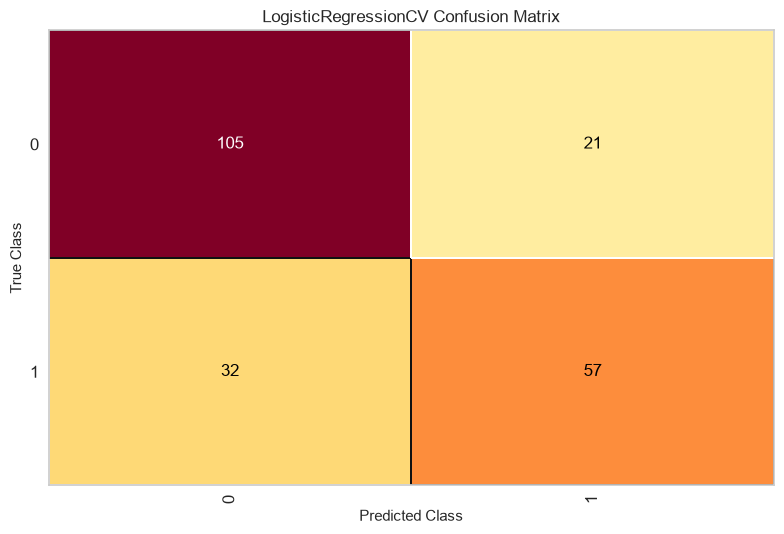

<Axes: title={'center': 'LogisticRegressionCV Confusion Matrix'}, xlabel='Predicted Class', ylabel='True Class'>

In [10]:
# initialize ConfusionMatrix using the trained model and binary classes (0 for does not survive, or 1 for does survive)
# force_model=True is used for Yellowbrick version compatibility
cm = ConfusionMatrix(clf, classes=[0,1], force_model=True)
# compute and evaluate the model's accuracy score on the test dataset using the ConfusionMatrix
cm.score(X_test, y_test)
# visualize the ConfusionMatrix to analyze true vs. predicted classifications
cm.show()

/opt/homebrew/anaconda3/lib/python3.12/site-packages/yellowbrick/classifier/base.py:232: YellowbrickWarning: could not determine class_counts_ from previously fitted classifier
  warnings.warn(


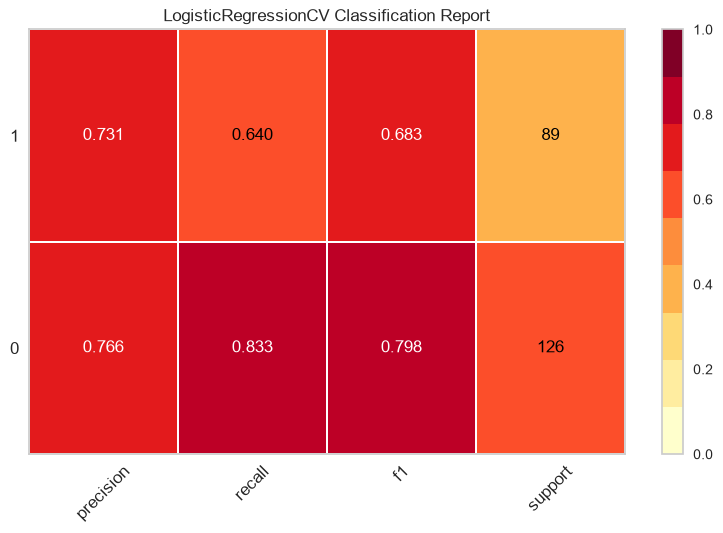

<Axes: title={'center': 'LogisticRegressionCV Classification Report'}>

In [11]:
# initialize the ClassificationReport using the trained model, binary classes (0 for does not survive, or 1 for does survive), 
# set support=True to display the count of true instances for each class, and force_model=True for version compatibility
report = ClassificationReport(clf, classes=[0,1], support=True, force_model=True)
# evaluate the model's classification performance on the test dataset using the visualizer
report.score(X_test, y_test)
# visualize the ClassificationReport to show the feature's precision, recall, F1-score, and support for each class
report.show()

## Part 2: Your Turn

### Wine Dataset Classification using Logistic RegressionCV and StandardScaler
In this assignment, you will be using the LogisticRegressionCV algorithm and StandardScaler to build a classification model that can predict the wine class. You will be using the "Wine Data Set" from the sklearn library, which contains information about the chemical composition of wines grown in the same region in Italy. You will preprocess the data, split it into training and testing sets, scale the data, train a logistic regression model using cross-validation, and evaluate the model's performance using a classification report.

#### Dataset
The "Wine Data Set" contains data about the chemical composition of wines grown in the same region in Italy. The dataset includes 178 rows and 13 columns, including the target variable "target", which indicates the wine class.

#### The other features in the dataset include:

- alcohol: the alcohol content of the wine
- malic_acid: the malic acid content of the wine
- ash: the ash content of the wine
- alcalinity_of_ash: the alcalinity of ash of the wine
- magnesium: the magnesium content of the wine
- total_phenols: the total phenols content of the wine
- flavanoids: the flavanoids content of the wine
- nonflavanoid_phenols: the nonflavanoid phenols content of the wine
- proanthocyanins: the proanthocyanins content of the wine
- color_intensity: the color intensity of the wine
- hue: the hue of the wine
- od280/od315_of_diluted_wines: the OD280/OD315 of diluted wines
- proline: the proline content of the wine

The target variable "target" has three classes:

- Class 0: 59 instances
- Class 1: 71 instances
- Class 2: 48 instances

Requirements
- Load the dataset into a pandas DataFrame.
- Split the dataset into training and testing sets, with 70% of the data for training and 30% for testing.
- Scale the numerical features using StandardScaler.
- Train a logistic regression model using cross-validation (LogisticRegressionCV) on the training data. Use a 5-fold cross-validation, and set the regularization parameter C to a value of 1.
- Evaluate the performance of the model on the testing data using a classification report, which includes precision, recall, f1-score, and support for each class.
- Interpret the results of the model

In [12]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from yellowbrick.classifier import ClassificationReport
import warnings
warnings.filterwarnings('ignore')

# Load the dataset into a pandas DataFrame
wine = load_wine()
X, y = wine.data, wine.target
feature_names = wine.feature_names

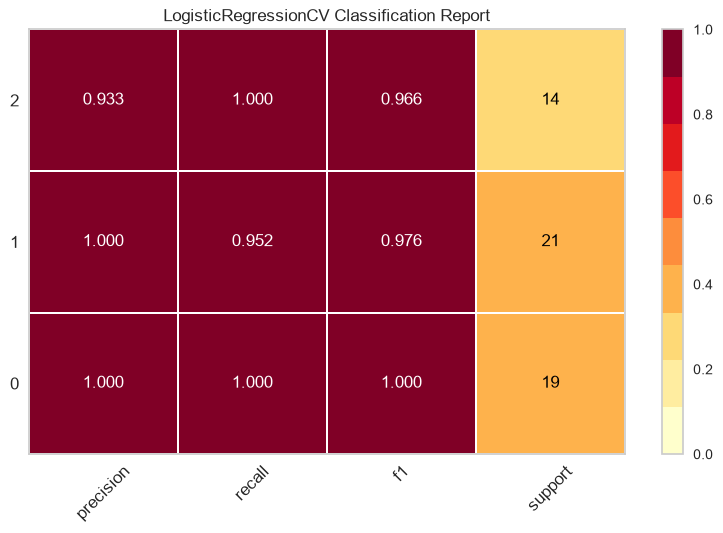

<Axes: title={'center': 'LogisticRegressionCV Classification Report'}>

In [13]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Preprocess the data using StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train the logistic regression model using cross-validation
classifier = LogisticRegressionCV(cv=5, solver='saga', max_iter=5000, random_state=42, l1_ratios=(0,), scoring='accuracy', use_legacy_attributes=False)
classifier.fit(X_train, y_train)

# Visualize precision, recall, and f1 scores using Yellowbrick
report = ClassificationReport(classifier, classes=[0, 1, 2], support=True, force_model=True)
report.score(X_test, y_test)
report.show()

The LogisticRegression model successfuly shows multi-class performance across all wine categories, recording F1-scores of 1.000 for Class 0 (19 samples), 0.976 for Class 1 (21 samples), and 0.966 for Class 2 (14 samples).